# Fase 4: Resultados

In [1]:
# Importar dependencias.
import constants
import matplotlib.pyplot as plt
import warnings
from IPython.display import display
from util import csv_util

# No mostrar mensajes de advertencia.
warnings.filterwarnings('ignore')

## 1. Deterioro diario

In [19]:
def load_dataset_1(path):
    df = csv_util.read(path, usecols=['date', 'city', 'section', 'roadway', 'direction', 'lane', 'total_stress', 'total_stress_pred'],
                       dtype={'city':str, 'section':int, 'roadway':int, 'direction':int, 'lane':int, 'total_stress':float, 'total_stress_pred':float},
                       date_formats=[('date', '%Y-%m-%d')])

    return df

def show_plot_1(model_name):
    # Cargar datos.
    df = load_dataset_1(f'model/{model_name}/result/{model_name}_results.csv')
    # Se toma un carril de ejemplo.
    df = df[(df['city'] == 'auckland') & (df['section'] == 1) & (df['roadway'] == 4264) & (df['direction'] == 1) & (df['lane'] == 1)]
    # Eliminar registros con valores nulos.
    df = df.dropna(subset=['total_stress'])
    # Asignar un valor más pequeño.
    df['total_stress'] = df['total_stress'] / 1e6
    df['total_stress_pred'] = df['total_stress_pred'] / 1e6
    # Crear la gráfica de regresión.
    plt.figure(figsize=(6, 6))
    plt.scatter(df['total_stress'], df['total_stress_pred'], alpha=0.3, color='blue')
    # Crear línea diagonal.
    min_val = min(df['total_stress'].min(), df['total_stress_pred'].min())
    max_val = max(df['total_stress'].max(), df['total_stress_pred'].max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Ideal (y = x)')
    # Crear leyendas.
    plt.xlabel('Deterioro real diario')
    plt.ylabel('Deterioro predicho diario')
    plt.title(f'{model_name}: Real vs. Predicción')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

### 1.1. LightGBM

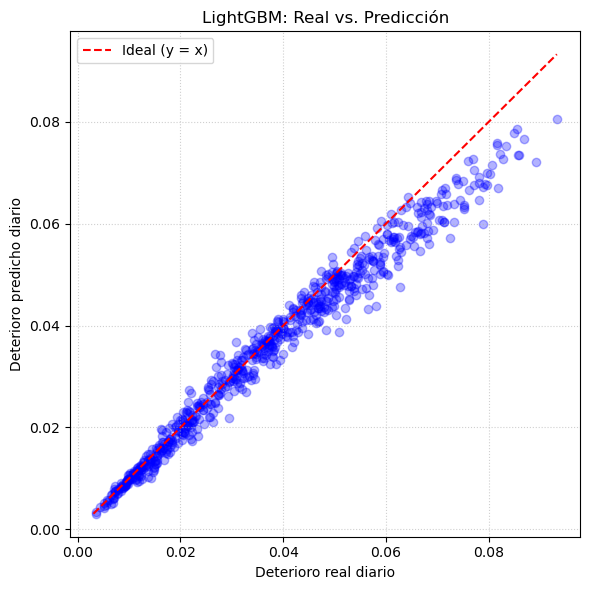

In [20]:
show_plot_1('LightGBM')

### 1.2. CatBoost

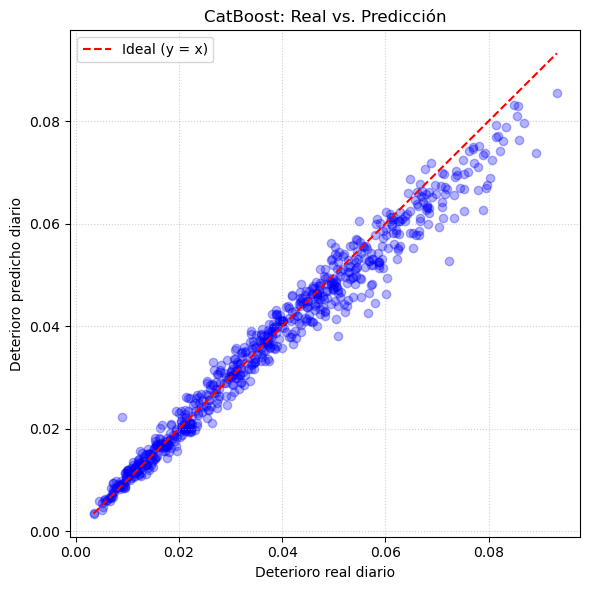

In [21]:
show_plot_1('CatBoost')

## 2. Deterioro acumulado

In [5]:
def load_dataset_2(path):
    df = csv_util.read(path, usecols=['date', 'city', 'section', 'roadway', 'direction', 'lane', 'total_stress', 'target_stress_30d', 'target_stress_30d_pred'],
                       dtype={'city':str, 'section':int, 'roadway':int, 'direction':int, 'lane':int, 'total_stress':float, 'target_stress_30d':float, 'target_stress_30d_pred':float},
                       date_formats=[('date', '%Y-%m-%d')])

    return df

def show_plot_2(model_name):
    # Cargar datos.
    df = load_dataset_2(f'model/{model_name}/result/{model_name}_results.csv')
    # Se toma un carril de ejemplo.
    df = df[(df['city'] == 'auckland') & (df['section'] == 1) & (df['roadway'] == 4264) & (df['direction'] == 1) & (df['lane'] == 1)]
    # Eliminar registros con valores nulos.
    df = df.dropna(subset=['target_stress_30d'])
    # Asignar un valor más pequeño.
    df['target_stress_30d'] = df['target_stress_30d'] / 1e6
    df['target_stress_30d_pred'] = df['target_stress_30d_pred'] / 1e6
    # Crear la gráfica de regresión.
    plt.figure(figsize=(6, 6))
    plt.scatter(df['target_stress_30d'], df['target_stress_30d_pred'], alpha=0.3, color='blue')
    # Crear línea diagonal.
    min_val = min(df['target_stress_30d'].min(), df['target_stress_30d_pred'].min())
    max_val = max(df['target_stress_30d'].max(), df['target_stress_30d_pred'].max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Ideal (y = x)')
    # Crear leyendas.
    plt.xlabel('Deterioro real acumulado')
    plt.ylabel('Deterioro predicho acumulado')
    plt.title(f'{model_name}: Real vs. Predicción')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

### 2.1. LSTM

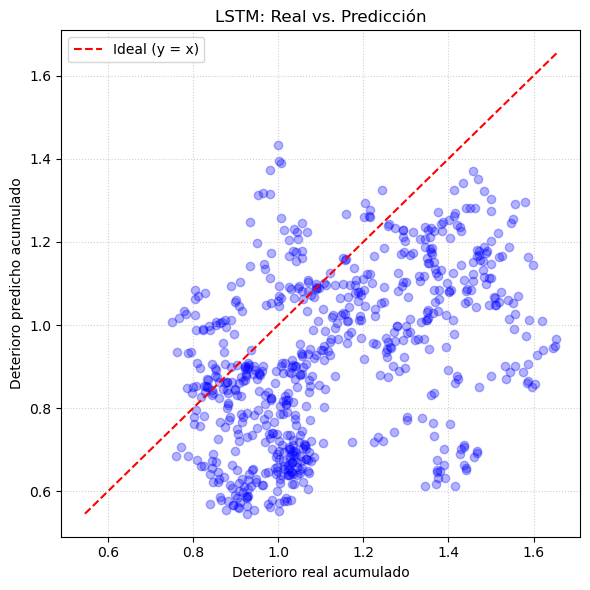

In [6]:
show_plot_2('LSTM')

### 2.2. Chronos-2

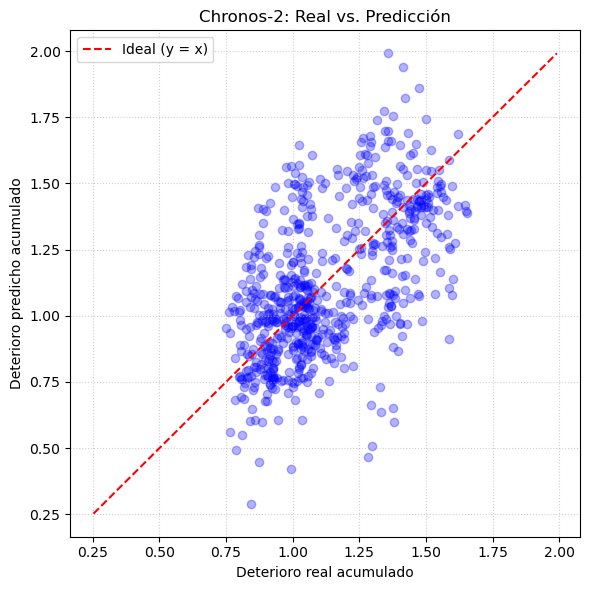

In [7]:
show_plot_2('Chronos-2')

## 3. Anomalías

In [14]:
for city in constants.CITIES:
    df = csv_util.read(f'model/Isolation_Forest/result/{city}_Isolation_Forest_results.csv',
                       usecols=['date', 'city', 'section', 'roadway', 'direction', 'lane', 'heavy_traffic', 'max_pavement_temperature', 'precipitation', 'total_stress'],
                       dtype={'city':str, 'section':int, 'roadway':int, 'direction':int, 'lane':int, 'heavy_traffic':float, 'max_pavement_temperature':float,
                              'precipitation':float, 'total_stress':float},
                       date_formats=[('date', '%Y-%m-%d')])
    print(f"{'-' * 50}\n Top estrés diario en {city.capitalize()} \n{'-' * 50}")
    # Ordenar para ver gravedad sin tener en cuenta resultados de los modelos.
    top_extreme_anomalies = df.sort_values(by='total_stress', ascending=False)
    # Ver los casos más críticos.
    display(top_extreme_anomalies.head(3))

--------------------------------------------------
 Top estrés diario en Auckland 
--------------------------------------------------


,date,city,section,roadway,direction,lane,heavy_traffic,max_pavement_temperature,precipitation,total_stress
8672,2018-11-30,auckland,3,6621,1,1,3078.5,68.201284,0.164,716500.119481
8750,2018-12-03,auckland,3,6621,1,1,2967.0,68.517813,0.590,707717.942799
8646,2018-11-29,auckland,3,6621,1,1,3179.0,64.373269,0.048,629210.868219


--------------------------------------------------
 Top estrés diario en Christchurch 
--------------------------------------------------


,date,city,section,roadway,direction,lane,heavy_traffic,max_pavement_temperature,precipitation,total_stress
31778,2022-11-01,christchurch,3,6941,1,1,3688.5,34.396286,0.083,316964.772678
31779,2022-11-01,christchurch,3,6941,2,1,3555.0,34.396286,0.083,305492.684525
31670,2022-10-26,christchurch,3,6941,1,1,2671.0,31.573715,0.000,237471.720803


### 3.1. Isolation Forest

In [9]:
for city in constants.CITIES:
    df = csv_util.read(f'model/Isolation_Forest/result/{city}_Isolation_Forest_results.csv',
                       usecols=['date', 'city', 'section', 'roadway', 'direction', 'lane', 'heavy_traffic', 'max_pavement_temperature', 'precipitation',
                                'total_stress', 'anomaly_flag', 'anomaly_score'],
                       dtype={'city':str, 'section':int, 'roadway':int, 'direction':int, 'lane':int, 'heavy_traffic':float, 'max_pavement_temperature':float,
                              'precipitation':float, 'total_stress':float, 'anomaly_flag':int, 'anomaly_score':float},
                       date_formats=[('date', '%Y-%m-%d')])
    # Filtrar por anomalías.
    anomalies = df[df['anomaly_flag'] == -1]
    print(f"{'-' * 50}\n Anomalías en {city.capitalize()} \n{'-' * 50}")
    print(f'Total de anomalías detectadas {city}: {len(anomalies)}')
    # Ordenar para ver gravedad.
    top_extreme_anomalies = anomalies.sort_values(by='anomaly_score', ascending=True)
    # Ver los casos más críticos.
    display(top_extreme_anomalies.head(3))

--------------------------------------------------
 Anomalías en Auckland 
--------------------------------------------------
Total de anomalías detectadas auckland: 2030


,date,city,section,roadway,direction,lane,heavy_traffic,max_pavement_temperature,precipitation,total_stress,anomaly_flag,anomaly_score
8750,2018-12-03,auckland,3,6621,1,1,2967.0,68.517813,0.590,707717.942799,-1,-0.209673
8748,2018-12-03,auckland,3,6603,2,1,2562.5,68.517813,0.590,611232.635127,-1,-0.195615
8672,2018-11-30,auckland,3,6621,1,1,3078.5,68.201284,0.164,716500.119481,-1,-0.191963


--------------------------------------------------
 Anomalías en Christchurch 
--------------------------------------------------
Total de anomalías detectadas christchurch: 1183


,date,city,section,roadway,direction,lane,heavy_traffic,max_pavement_temperature,precipitation,total_stress,anomaly_flag,anomaly_score
31778,2022-11-01,christchurch,3,6941,1,1,3688.5,34.396286,0.083,316964.772678,-1,-0.154350
31779,2022-11-01,christchurch,3,6941,2,1,3555.0,34.396286,0.083,305492.684525,-1,-0.146886
36534,2023-07-23,christchurch,4,7981,2,1,1300.5,10.807127,3.108,31406.443022,-1,-0.142019


### 3.2. One-Class SVM

In [11]:
for city in constants.CITIES:
    df = csv_util.read(f'model/One-Class_SVM/result/{city}_One-Class_SVM_results.csv',
                       usecols=['date', 'city', 'section', 'roadway', 'direction', 'lane', 'heavy_traffic', 'max_pavement_temperature', 'precipitation',
                                'total_stress', 'oc_svm_anomaly', 'oc_svm_score'],
                       dtype={'city':str, 'section':int, 'roadway':int, 'direction':int, 'lane':int, 'heavy_traffic':float, 'max_pavement_temperature':float,
                              'precipitation':float, 'total_stress':float, 'oc_svm_anomaly':int, 'oc_svm_score':float},
                       date_formats=[('date', '%Y-%m-%d')])
    # Filtrar por anomalías.
    print(f"{'-' * 50}\n Anomalías en {city.capitalize()} \n{'-' * 50}")
    print(f"Total de anomalías detectadas {city}: {df['oc_svm_anomaly'].value_counts().get(1, 0)}")
    # Ordenar para ver gravedad.
    top_extreme_anomalies = df[df['oc_svm_anomaly'] == 1].sort_values(by='oc_svm_score', ascending=True)
    # Ver los casos más críticos.
    display(top_extreme_anomalies.head(3))

--------------------------------------------------
 Anomalías en Auckland 
--------------------------------------------------
Total de anomalías detectadas auckland: 3769


,date,city,section,roadway,direction,lane,heavy_traffic,max_pavement_temperature,precipitation,total_stress,oc_svm_anomaly,oc_svm_score
48192,2023-01-28,auckland,3,6621,1,1,1215.5,31.867931,6.487,47488.370006,1,-1941.467003
48184,2023-01-28,auckland,2,2070,1,3,1117.0,31.867931,6.487,24937.184837,1,-1941.403122
48183,2023-01-28,auckland,2,2070,1,2,1064.0,31.867931,6.487,23753.952253,1,-1941.372194


--------------------------------------------------
 Anomalías en Christchurch 
--------------------------------------------------
Total de anomalías detectadas christchurch: 2622


,date,city,section,roadway,direction,lane,heavy_traffic,max_pavement_temperature,precipitation,total_stress,oc_svm_anomaly,oc_svm_score
48198,2025-05-01,christchurch,4,7981,2,1,1068.5,9.397689,3.150,17221.004375,1,-1702.012135
48203,2025-05-01,christchurch,5,478059,2,2,985.5,9.397689,3.150,9076.168092,1,-1701.941048
30018,2022-07-26,christchurch,4,7981,2,1,1173.0,10.253997,3.149,28047.119692,1,-1701.931308
